# E-commerce orders and transactions: exploratory data analysis

This notebook explores the local `ecommerce_orders_transactions_2026.csv` file. It checks data quality, summarizes sales and profitability, and compares trends across time, products, customers, regions, and operations. Values are not assumed in advance; inspect the outputs before drawing conclusions.

> Sales metrics below use the dataset's provided fields. The row-level structure may be order-line or transaction-level, so order counts use distinct `Order_ID` values where relevant.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

DATA_FILE = Path("ecommerce_orders_transactions_2026.csv")
if not DATA_FILE.exists():
    matches = list(Path.cwd().glob("**/ecommerce_orders_transactions_2026.csv"))
    if not matches:
        raise FileNotFoundError("Could not find ecommerce_orders_transactions_2026.csv under the notebook's working directory.")
    DATA_FILE = matches[0]

df = pd.read_csv(DATA_FILE, low_memory=False)
print(f"Loaded {DATA_FILE.resolve()}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
display(df.head())

Loaded C:\Users\sulaiman.at\Documents\GitHub\E-commerce-Analytics\ecommerce_orders_transactions_2026.csv
Shape: 200,000 rows x 50 columns
     Order_ID  Order_Date Order_Time  Customer_ID Customer_Name  Customer_Age Customer_Gender Customer_Country Customer_Continent Customer_City   Customer_Region  Customer_Segment   Product_ID            SKU                        Product_Name   Product_Category Product_Subcategory      Brand  Quantity  Unit_Price_USD  Gross_Sales_USD  Discount_Percentage  Discount_Amount_USD  Net_Sales_USD  Tax_Rate_Percentage  Tax_USD  Shipping_Cost_USD  Total_Order_Value_USD     Payment_Method Payment_Status Order_Status Shipping_Method  Delivery_Days Return_Status Return_Reason Marketing_Channel Device_Type  Coupon_Used Coupon_Code  Customer_Rating Review_Sentiment  Is_Repeat_Customer   Sales_Region  Warehouse                           Supplier  Order_Profit_USD  Profit_Margin_Percentage  Is_Bestseller_Product  Is_New_Customer  Is_First_Order
0  ORD-105927  2026-

## 1. Structure and data quality

Check column types, missingness, duplicate rows, and identifier cardinality before relying on any aggregation.

In [2]:
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True),
}).sort_values(["missing_pct", "unique"], ascending=[False, True]))

print(f"Exact duplicate rows: {df.duplicated().sum():,}")
for col in ["Order_ID", "Customer_ID", "Product_ID"]:
    if col in df.columns:
        print(f"Distinct {col}: {df[col].nunique(dropna=True):,} (missing: {df[col].isna().sum():,})")

display(df.describe(include="all").T)

                            dtype  non_null  missing  missing_pct  unique
Return_Reason              object      8330   191670        95.84       8
Coupon_Code                object     29835   170165        85.08      12
Return_Status              object    200000        0         0.00       2
Coupon_Used                  bool    200000        0         0.00       2
Is_Repeat_Customer           bool    200000        0         0.00       2
Is_Bestseller_Product        bool    200000        0         0.00       2
Is_New_Customer              bool    200000        0         0.00       2
Is_First_Order               bool    200000        0         0.00       2
Device_Type                object    200000        0         0.00       3
Review_Sentiment           object    200000        0         0.00       3
Customer_Gender            object    200000        0         0.00       4
Payment_Status             object    200000        0         0.00       4
Quantity                    int64    2

## 2. Prepare analysis fields

Convert dates and numeric measures explicitly. Invalid parsed values become missing and should be considered when interpreting results.

In [3]:
if "Order_Date" in df.columns:
    df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

numeric_candidates = [
    "Customer_Age", "Quantity", "Unit_Price_USD", "Gross_Sales_USD",
    "Discount_Percentage", "Discount_Amount_USD", "Net_Sales_USD",
    "Tax_Rate_Percentage", "Tax_USD", "Shipping_Cost_USD",
    "Total_Order_Value_USD", "Delivery_Days", "Customer_Rating",
    "Order_Profit_USD", "Profit_Margin_Percentage",
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "Order_Date" in df.columns:
    df["Order_Month"] = df["Order_Date"].dt.to_period("M").dt.to_timestamp()

available_measures = [col for col in numeric_candidates if col in df.columns]
display(df[available_measures].describe().T)
if "Order_Date" in df.columns:
    print(f"Parsed order dates: {df['Order_Date'].notna().sum():,} / {len(df):,}")
    print(f"Date range: {df['Order_Date'].min()} to {df['Order_Date'].max()}")

                              count   mean    std       min   25%    50%    75%      max
Customer_Age             200,000.00  46.47  16.74     18.00 32.00  46.00  61.00    75.00
Quantity                 200,000.00   2.10   1.18      1.00  1.00   2.00   3.00     5.00
Unit_Price_USD           200,000.00 285.85 377.00      5.00 50.02  93.76 348.42 1,499.28
Gross_Sales_USD          200,000.00 600.89 970.30      5.00 79.25 199.38 672.31 7,494.35
Discount_Percentage      200,000.00  12.03  10.34      0.00  5.00  10.00  20.00    40.00
Discount_Amount_USD      200,000.00  72.19 164.84      0.00  2.67  15.46  61.29 2,988.22
Net_Sales_USD            200,000.00 528.70 861.97      3.30 68.67 177.40 584.84 7,494.35
Tax_Rate_Percentage      200,000.00  15.69   6.74      0.00 10.00  17.00  21.00    27.00
Tax_USD                  200,000.00  82.91 151.31      0.00  8.73  25.13  83.11 1,875.92
Shipping_Cost_USD        200,000.00  15.79  10.55      3.00  8.68  13.34  18.84    60.00
Total_Order_Value_USD

## 3. Top-level business metrics

Revenue, order value, and profit fields are kept distinct: for example, `Net_Sales_USD` is not interchangeable with `Total_Order_Value_USD`. Validate each field's definition against the source data documentation before external reporting.

In [4]:
def available_sum(column):
    return df[column].sum(min_count=1) if column in df.columns else np.nan

kpis = {
    "Rows": len(df),
    "Distinct orders": df["Order_ID"].nunique(dropna=True) if "Order_ID" in df.columns else np.nan,
    "Distinct customers": df["Customer_ID"].nunique(dropna=True) if "Customer_ID" in df.columns else np.nan,
    "Net sales (USD)": available_sum("Net_Sales_USD"),
    "Total order value (USD)": available_sum("Total_Order_Value_USD"),
    "Order profit (USD)": available_sum("Order_Profit_USD"),
    "Average net sales per row (USD)": df["Net_Sales_USD"].mean() if "Net_Sales_USD" in df.columns else np.nan,
    "Average order value (USD)": (
        df.groupby("Order_ID", dropna=True)["Total_Order_Value_USD"].sum().mean()
        if {"Order_ID", "Total_Order_Value_USD"}.issubset(df.columns) else np.nan
    ),
}
display(pd.Series(kpis, name="Value").to_frame())

if "Order_Status" in df.columns:
    display(df["Order_Status"].value_counts(dropna=False).rename_axis("Order_Status").to_frame("rows"))

                                         Value
Rows                                200,000.00
Distinct orders                     200,000.00
Distinct customers                   69,728.00
Net sales (USD)                 105,739,089.34
Total order value (USD)         125,478,421.59
Order profit (USD)               30,494,093.62
Average net sales per row (USD)         528.70
Average order value (USD)               627.39
                rows
Order_Status        
Delivered     140112
Processing     19887
Shipped        15987
Cancelled      12019
Returned       11995


## 4. Sales and profitability distributions

Inspect skew and outliers in key numeric measures. The box plots use a robust display range (1st–99th percentile) while the full distributions remain summarized above.

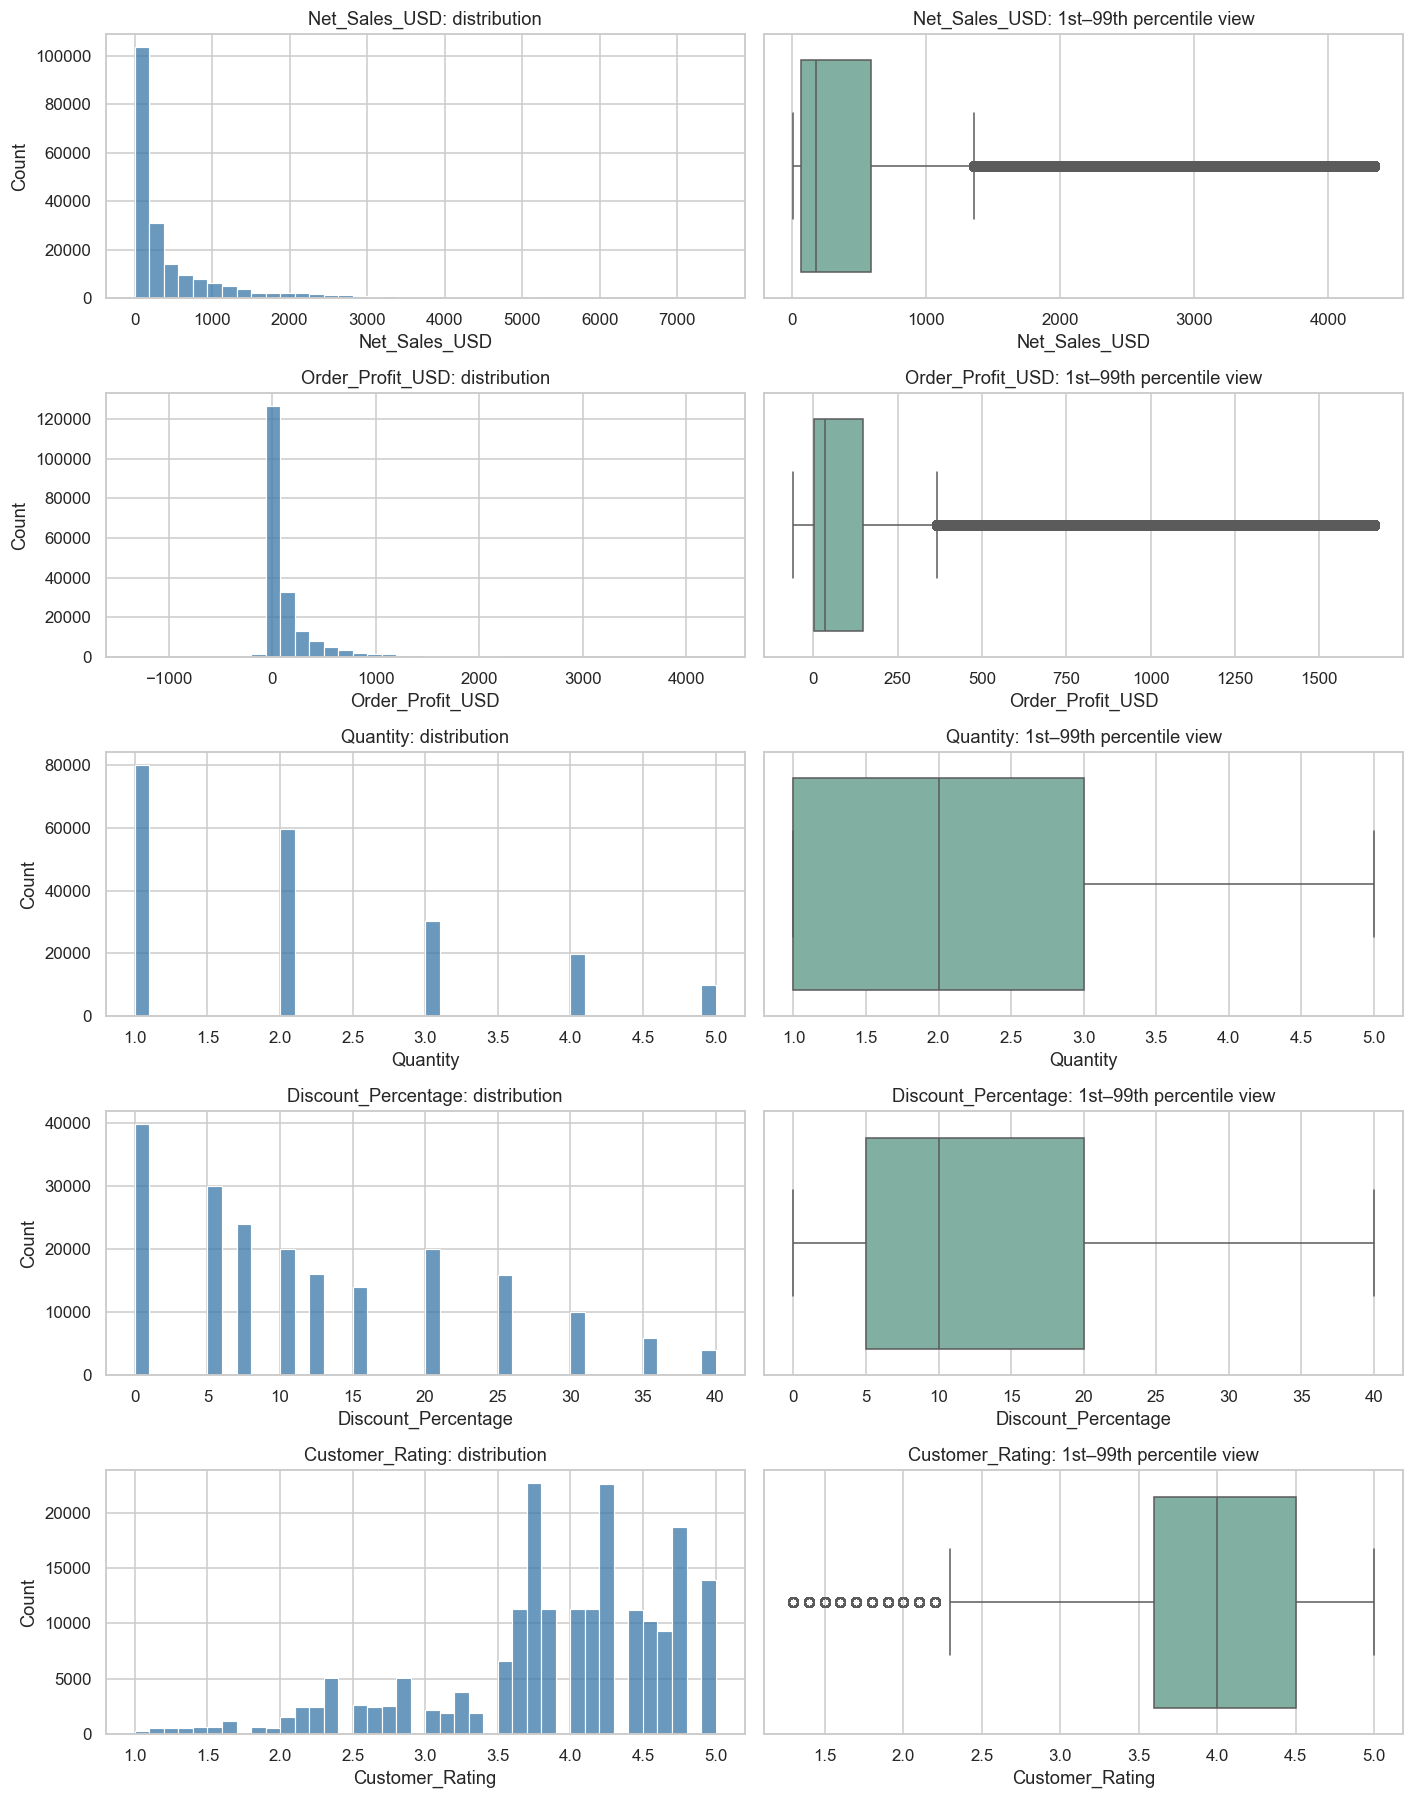

In [5]:
distribution_cols = [c for c in ["Net_Sales_USD", "Order_Profit_USD", "Quantity", "Discount_Percentage", "Customer_Rating"] if c in df.columns]
if distribution_cols:
    fig, axes = plt.subplots(len(distribution_cols), 2, figsize=(13, 3.3 * len(distribution_cols)))
    if len(distribution_cols) == 1:
        axes = np.array([axes])
    for row, col in enumerate(distribution_cols):
        values = df[col].dropna()
        if not values.empty:
            sns.histplot(values, bins=40, ax=axes[row, 0], color="#3977a8")
            axes[row, 0].set_title(f"{col}: distribution")
            low, high = values.quantile([0.01, 0.99])
            sns.boxplot(x=values.clip(lower=low, upper=high), ax=axes[row, 1], color="#79b7a5")
            axes[row, 1].set_title(f"{col}: 1st–99th percentile view")
    plt.tight_layout()
    plt.show()

## 5. Trends over time

Monthly totals show how sales and profit change over the date range. If data is incomplete at the start or end of the period, compare only full periods.

             orders     net_sales       profit  units
Order_Month                                          
2026-01-01    12075  6,426,767.06 1,880,701.45  25133
2026-02-01    11962  6,261,321.99 1,794,093.94  25168
2026-03-01    13959  7,411,058.04 2,160,048.94  29201
2026-04-01    13890  7,556,877.59 2,196,620.49  29415
2026-05-01    16277  8,466,119.52 2,378,521.60  34141
2026-06-01    15759  8,309,132.51 2,403,788.32  32886
2026-07-01    16108  8,467,118.75 2,440,544.85  33815
2026-08-01    18429  9,755,730.80 2,808,246.74  38523
2026-09-01    17788  9,346,980.76 2,687,782.19  37398
2026-10-01    20705 10,770,202.06 3,092,602.40  43434
2026-11-01    21790 11,621,515.53 3,373,584.38  46125
2026-12-01    21258 11,346,264.73 3,277,558.32  44703


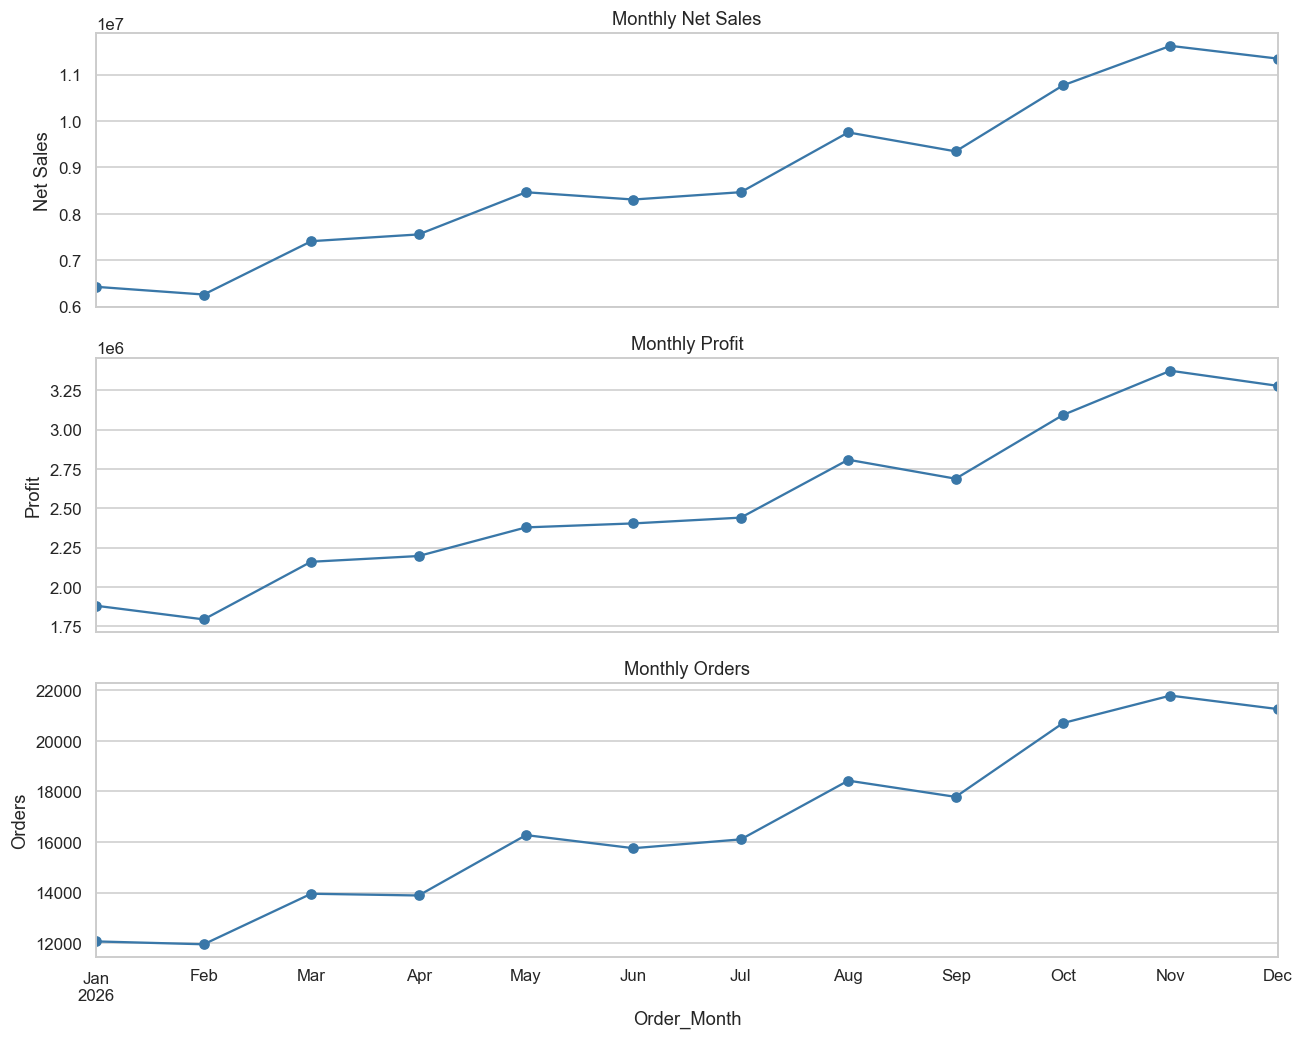

In [6]:
if {"Order_Month", "Order_ID"}.issubset(df.columns):
    monthly_spec = {"orders": ("Order_ID", "nunique")}
    for source, name in [("Net_Sales_USD", "net_sales"), ("Order_Profit_USD", "profit"), ("Quantity", "units")]:
        if source in df.columns:
            monthly_spec[name] = (source, "sum")
    monthly = df.dropna(subset=["Order_Month"]).groupby("Order_Month").agg(**monthly_spec).sort_index()
    display(monthly)
    plot_cols = [c for c in ["net_sales", "profit", "orders"] if c in monthly.columns]
    if plot_cols:
        fig, axes = plt.subplots(len(plot_cols), 1, figsize=(12, 3.2 * len(plot_cols)), sharex=True)
        axes = np.atleast_1d(axes)
        for ax, col in zip(axes, plot_cols):
            monthly[col].plot(ax=ax, marker="o", color="#3977a8")
            ax.set_title(f"Monthly {col.replace('_', ' ').title()}")
            ax.set_ylabel(col.replace("_", " ").title())
        plt.tight_layout()
        plt.show()
else:
    print("Order_Month and/or Order_ID unavailable; monthly trend analysis skipped.")

## 6. Product and category performance

Compare category and product contribution to net sales and profit. Summed sales are row-based; distinct order counts avoid counting repeated order lines as separate orders.


### Product_Category
                         orders     net_sales       profit  units
Product_Category                                                 
Electronics               20577 28,535,620.09 8,749,423.35  43181
Mobile Phones             17254 24,628,033.91 7,843,766.57  36137
Computers & Accessories   16571 23,146,477.00 6,970,268.92  34972
Home & Kitchen            16533  7,902,874.57 2,243,801.78  34839
Fashion                   19664  5,747,821.80 1,483,977.46  41045
Furniture                 10568  4,823,933.61 1,313,614.37  22153
Jewelry & Accessories      6654  1,922,297.37   493,846.64  13881
Beauty & Personal Care    13991  1,355,817.51   190,791.41  29513
Sports & Fitness          10708  1,049,706.72   159,302.92  22519
Books                      9993    943,343.40   140,117.03  20893
Toys & Games               9395    911,822.71   144,202.13  19536
Health & Wellness          6653    657,708.33   105,952.46  14055

### Product_Subcategory
                     orders  

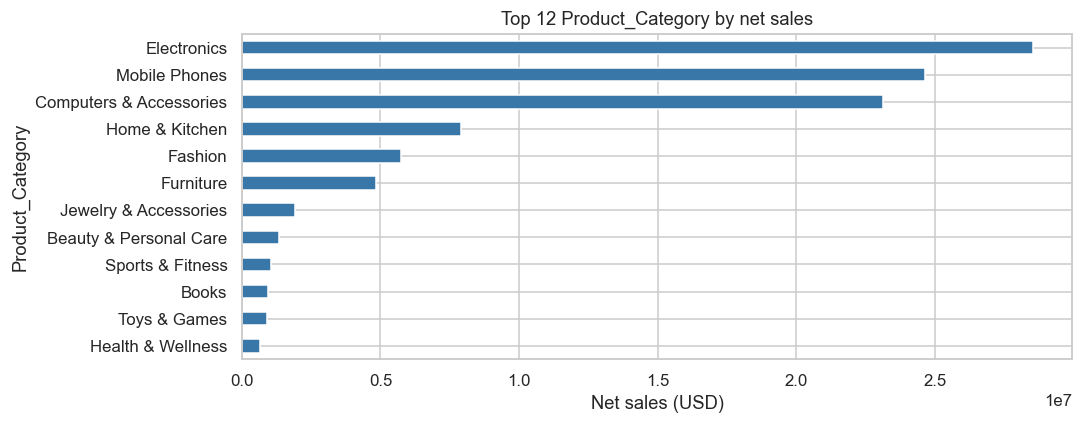

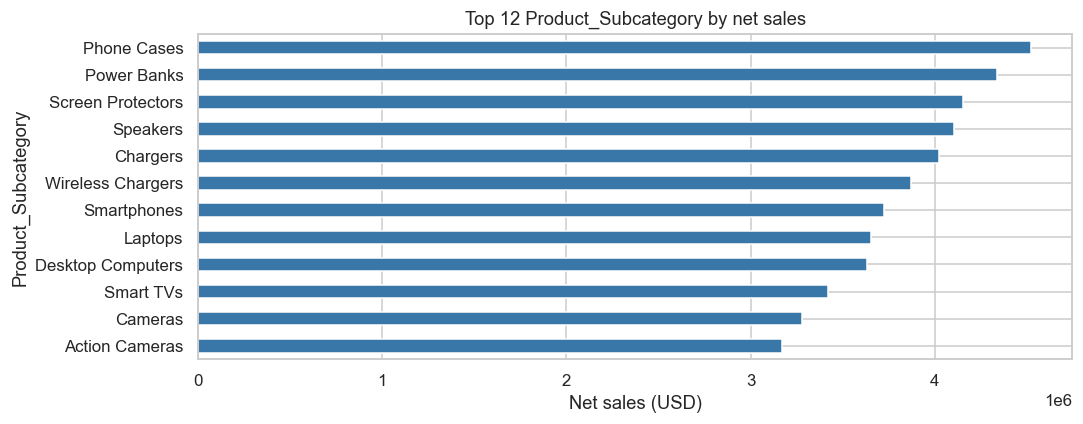

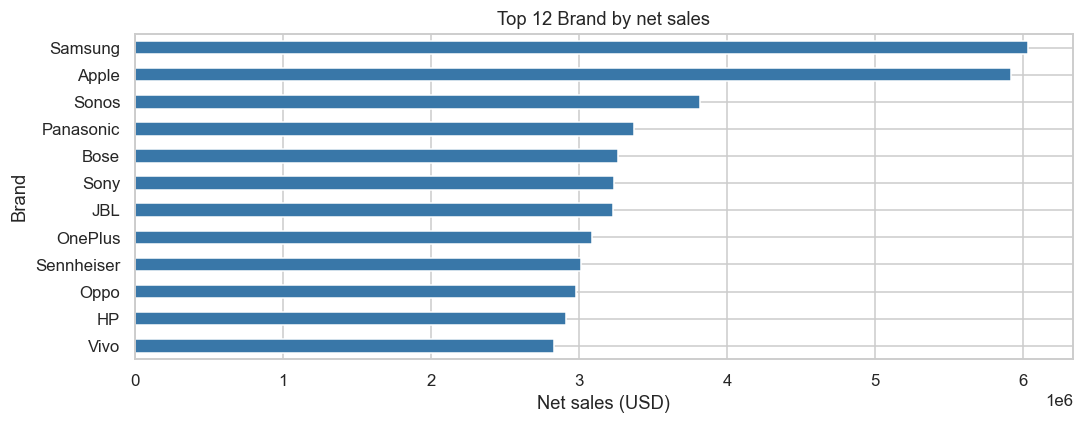

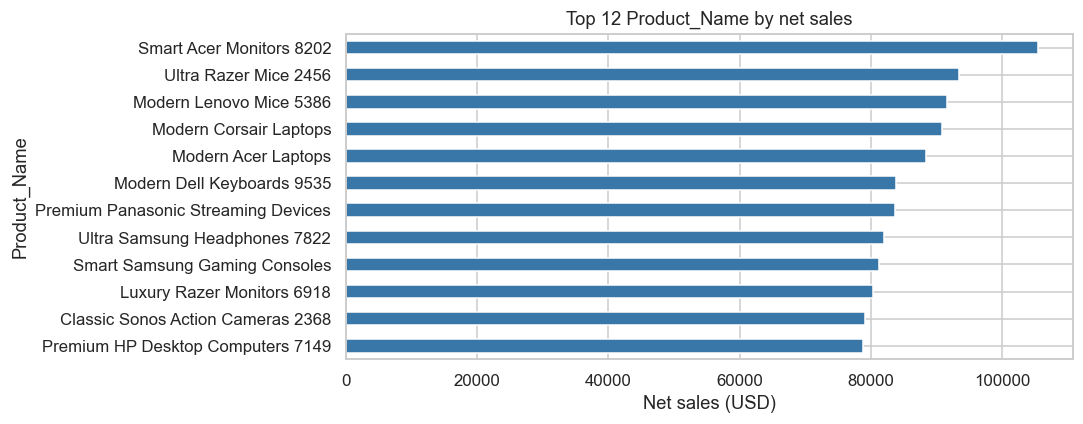

In [7]:
def grouped_performance(group_col, top_n=15):
    if group_col not in df.columns:
        print(f"{group_col} not available.")
        return
    agg = {}
    if "Order_ID" in df.columns:
        agg["orders"] = ("Order_ID", "nunique")
    for source, name in [("Net_Sales_USD", "net_sales"), ("Order_Profit_USD", "profit"), ("Quantity", "units")]:
        if source in df.columns:
            agg[name] = (source, "sum")
    if not agg:
        print("No compatible measures available.")
        return
    sort_column = "net_sales" if "net_sales" in agg else next(iter(agg))
    result = df.groupby(group_col, dropna=False).agg(**agg).sort_values(sort_column, ascending=False)
    display(result.head(top_n))
    if "net_sales" in result.columns:
        result["net_sales"].head(top_n).sort_values().plot(kind="barh", figsize=(10, max(4, top_n * 0.28)), color="#3977a8")
        plt.title(f"Top {top_n} {group_col} by net sales")
        plt.xlabel("Net sales (USD)")
        plt.tight_layout()
        plt.show()

for dimension in ["Product_Category", "Product_Subcategory", "Brand", "Product_Name"]:
    if dimension in df.columns:
        print(f"\n### {dimension}")
        grouped_performance(dimension, top_n=12)

## 7. Customer and market segments

Compare customer segment, country/region, marketing channel, and payment method. Interpret these as descriptive associations, not causal effects.

In [8]:
for dimension in ["Customer_Segment", "Customer_Continent", "Customer_Country", "Sales_Region", "Marketing_Channel", "Payment_Method", "Device_Type"]:
    if dimension not in df.columns:
        continue
    print(f"\n### {dimension}")
    agg = {}
    if "Order_ID" in df.columns:
        agg["orders"] = ("Order_ID", "nunique")
    if "Customer_ID" in df.columns:
        agg["customers"] = ("Customer_ID", "nunique")
    if "Net_Sales_USD" in df.columns:
        agg["net_sales"] = ("Net_Sales_USD", "sum")
    if "Order_Profit_USD" in df.columns:
        agg["profit"] = ("Order_Profit_USD", "sum")
    if agg:
        display(df.groupby(dimension, dropna=False).agg(**agg).sort_values(
            "net_sales" if "net_sales" in agg else next(iter(agg)), ascending=False
        ).head(15))


### Customer_Segment
                  orders  customers     net_sales        profit
Customer_Segment                                               
Regular Customer   70528      24580 37,217,870.49 10,727,893.37
New Customer       60267      20875 31,921,843.43  9,211,783.12
Premium Customer   29730      10428 15,703,739.72  4,516,105.25
At-Risk Customer   19387       6843 10,348,088.45  3,017,476.50
VIP Customer       10191       3526  5,421,372.82  1,558,497.58
Dormant Customer    9897       3476  5,126,174.43  1,462,337.80

### Customer_Continent
                    orders  customers     net_sales        profit
Customer_Continent                                               
Europe               74381      25889 39,273,027.14 11,279,947.97
Asia                 70019      24472 37,183,633.65 10,770,957.67
Africa               19991       6936 10,462,735.17  3,042,963.60
South America        15939       5577  8,485,069.74  2,429,915.31
North America        11794       4088  6,145,1

## 8. Discounts, returns, and fulfillment

Review whether higher discounts coincide with different sales/profit outcomes and compare return and delivery patterns. Grouped results are observational and may reflect product or customer mix.

In [9]:
if {"Discount_Percentage", "Net_Sales_USD"}.issubset(df.columns):
    df["Discount_Band"] = pd.cut(
        df["Discount_Percentage"], bins=[-np.inf, 0, 5, 10, 20, 50, np.inf],
        labels=["0 or less", "0-5", "5-10", "10-20", "20-50", "50+"], include_lowest=True
    )
    discount_agg = {"rows": ("Net_Sales_USD", "size"), "avg_net_sales": ("Net_Sales_USD", "mean")}
    if "Order_Profit_USD" in df.columns:
        discount_agg["profit"] = ("Order_Profit_USD", "sum")
    display(df.groupby("Discount_Band", observed=False, dropna=False).agg(**discount_agg))

if "Return_Status" in df.columns:
    display(df["Return_Status"].value_counts(dropna=False).rename_axis("Return_Status").to_frame("rows"))
    if "Return_Reason" in df.columns:
        display(df.groupby(["Return_Status", "Return_Reason"], dropna=False).size().rename("rows").sort_values(ascending=False).head(20).to_frame())
    if "Order_Status" in df.columns:
        print("Order status vs. return status (row counts):")
        display(pd.crosstab(df["Order_Status"], df["Return_Status"], dropna=False, margins=True))

if "Delivery_Days" in df.columns:
    print("Delivery days summary:")
    display(df["Delivery_Days"].describe().to_frame())
    if "Shipping_Method" in df.columns:
        display(df.groupby("Shipping_Method", dropna=False)["Delivery_Days"].agg(["count", "mean", "median", "min", "max"]).sort_values("median"))

if {"Return_Status", "Product_Category"}.issubset(df.columns):
    return_rates = pd.crosstab(df["Product_Category"], df["Return_Status"], normalize="index") * 100
    display(return_rates.round(2))

                rows  avg_net_sales       profit
Discount_Band                                   
0 or less      39930         602.56 9,010,234.98
0-5            30090         562.91 5,770,745.25
5-10           44082         551.81 7,652,359.62
10-20          50080         508.18 6,427,223.33
20-50          35818         417.84 1,633,530.44
50+                0            NaN         0.00
                 rows
Return_Status        
No Return      191670
Returned         8330
                                         rows
Return_Status Return_Reason                  
No Return     NaN                      191670
Returned      Changed Mind               1088
              Damaged During Shipping    1069
              Late Delivery              1053
              Quality Issue              1047
              Defective Product          1033
              Wrong Size                 1015
              Not as Described           1014
              Wrong Item                 1011
Order status v

## 9. Correlations and interpretation checklist

The heatmap is a quick view of linear associations among numeric measures. Correlation does not imply causation; check definitions, outliers, and segment mix before acting on patterns.

Use the outputs above to note: (1) data-quality limitations, (2) strongest sales/profit categories and markets, (3) time periods with notable changes, and (4) return or delivery patterns that may warrant follow-up.

                          Quantity  Unit_Price_USD  Gross_Sales_USD  Discount_Percentage  Discount_Amount_USD  Net_Sales_USD  Tax_USD  Shipping_Cost_USD  Delivery_Days  Customer_Rating  Order_Profit_USD  Profit_Margin_Percentage
Quantity                      1.00            0.00             0.35                -0.00                 0.25           0.34     0.31              -0.00          -0.00            -0.00              0.29                      0.19
Unit_Price_USD                0.00            1.00             0.82                -0.00                 0.58           0.81     0.72               0.00          -0.00             0.00              0.69                      0.27
Gross_Sales_USD               0.35            0.82             1.00                -0.00                 0.71           0.99     0.89               0.00          -0.00            -0.00              0.84                      0.23
Discount_Percentage          -0.00           -0.00            -0.00                 

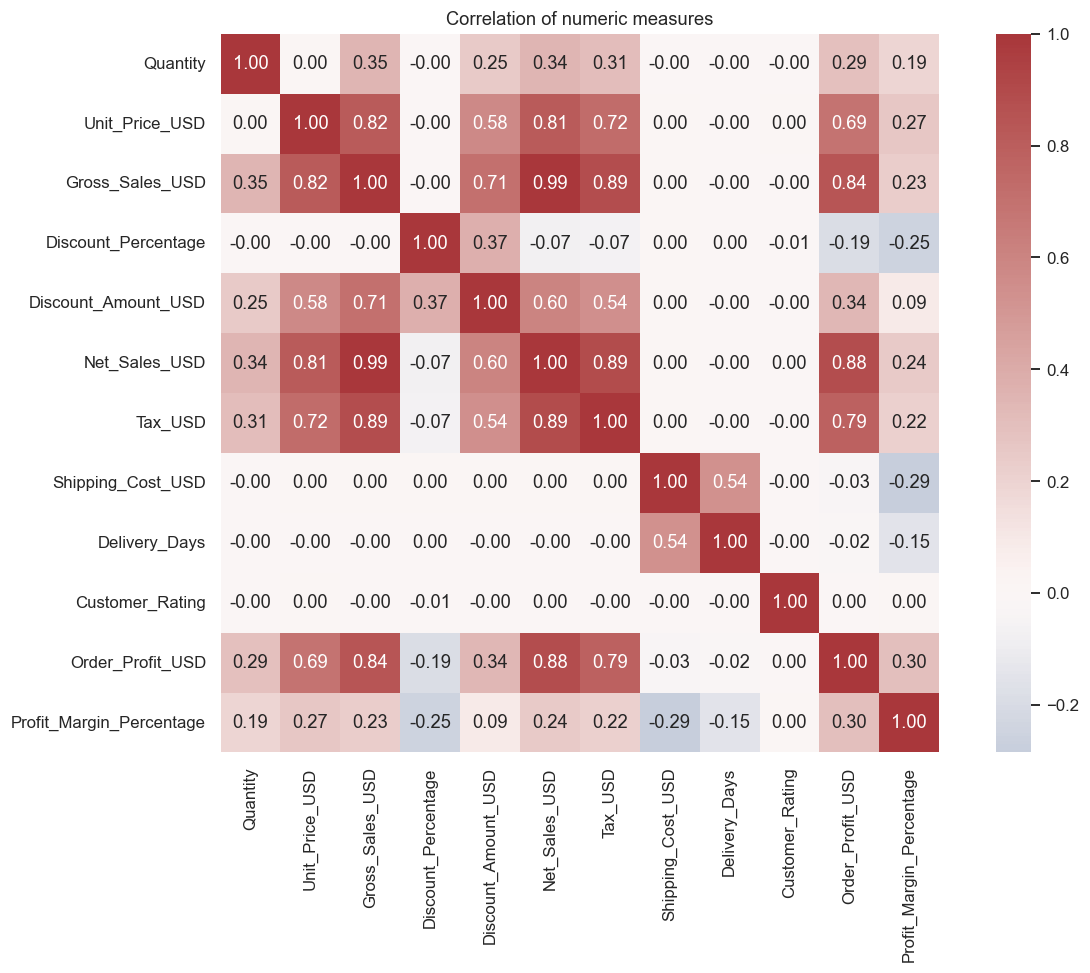

In [10]:
correlation_cols = [c for c in [
    "Quantity", "Unit_Price_USD", "Gross_Sales_USD", "Discount_Percentage",
    "Discount_Amount_USD", "Net_Sales_USD", "Tax_USD", "Shipping_Cost_USD",
    "Delivery_Days", "Customer_Rating", "Order_Profit_USD", "Profit_Margin_Percentage",
] if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
if len(correlation_cols) >= 2:
    corr = df[correlation_cols].corr(numeric_only=True)
    plt.figure(figsize=(12, 9))
    sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", square=True)
    plt.title("Correlation of numeric measures")
    plt.tight_layout()
    plt.show()
    display(corr)
else:
    print("Not enough numeric measures for a correlation matrix.")

## Initial findings from this dataset

- The file contains **200,000 rows and 50 columns**, with order dates spanning **January 1 through December 31, 2026**. The date range extends beyond the current analysis date; verify whether later-dated records are forecast, synthetic, or otherwise expected.
- The loaded records have **200,000 distinct orders** and **69,728 distinct customers**. The observed total is **$105.74M net sales**, **$125.48M total order value**, and **$30.49M order profit**; average order value is **$627.39** using the provided total-order-value field.
- The largest single month by net sales is **November 2026 ($11.62M)**, while December records **$11.35M**. Monthly totals are descriptive and could be affected by the future-dated records noted above.
- `Return_Reason` is missing on **95.84%** of rows and `Coupon_Code` on **85.08%**; interpret these as potentially conditional fields (e.g., only populated for returns/coupon orders), not necessarily general data defects.
- `Order_Status` has **11,995** rows labeled `Returned`, while `Return_Status` has **8,330** rows labeled `Returned`. The cross-tab in the returns section makes this distinction inspectable; reconcile the two status definitions before using either as a return-rate denominator.

These are descriptive observations, not causal conclusions. Review field definitions and business rules before reporting metrics.